<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" width="240" alt="Query.Farm"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" width="150" alt="VGI"></a>

# Do two scholarly searches describe the same set of works?

Search OpenAlex and Crossref for **“attention is all you need transformer”**, keep their metadata separate, then join only exact normalized DOIs. Inspect the availability of identifiers and dates before comparing citation counts. Finally, move the minimum publication year and measure how the overlap changes.

The default replays **two unchanged public API responses captured on 14 November 2026**, each containing 50 search results. The real Scholar worker parses them through VGI; SQL performs the filtering, identity audit and join. Search relevance is not a systematic literature review, and citation counts are provider observations, not research quality scores. [Setup and provenance](README.md).

## Choose the publication window

`MIN_YEAR` is an inclusive publication-year lower bound, integer **1900–2030**. Start at **2022**; the focused experiment uses **2024**. Unknown years remain visible in diagnostics and are excluded from the dated comparison. Each provider supplies its own year, so a shared DOI must pass the window independently in both.

`DATA_MODE` is **replay** or **live**. Query and retrieval budget stay fixed at 50 rows per provider. The year filter is applied **after retrieval**; it does not ask either API to search a different year range. Restart and run all after changing parameters. A live source refresh is a separate change from the year experiment.

In [1]:
DATA_MODE = "replay"  # Set "live" for direct requests, with no fallback.
MIN_YEAR = 2022  # Inclusive lower year; focused experiment: 2024.

In [2]:
import haybarn
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

from notebook_support import audit, chart, cleanup, configure, prose, theme

server, thread, previous, run_utc, provenance = configure(DATA_MODE, MIN_YEAR)
source_label = (
    "Recorded OpenAlex + Crossref • 2026-11-14 UTC"
    if DATA_MODE == "replay"
    else f"Live OpenAlex + Crossref • {run_utc[:19]} UTC"
)
theme()
connection = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.displaylimit = 55
%sql connection

/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/lane-2/vgi-scholar/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:339: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of ':variable' with '\:variable' and
/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/lane-2/vgi-scholar/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:369: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of 'example'[x:y] with 'example'[x\:y].


Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/lane-2/vgi-scholar/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/lane-2/vgi-scholar/notebooks/pyproject.toml.

## Connect to the pinned public worker

This remotely available Git revision includes explicit Crossref relevance sorting for cursor requests. The literal launch pins Python, SDK, Arrow and HTTP dependencies. The first run needs internet for Git/packages and the extension. All local companions live beside this notebook; no worker checkout is required.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'scholar' (TYPE vgi,
    LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-scholar@66200a4d3e0b6b3360a67ef040b99d9b99fd3365 --with vgi-python==0.51.0 --with vgi-rpc==0.53.1 --with pyarrow==26.0.1 --with httpx==0.28.1 vgi-scholar-worker');
CREATE TABLE settings AS SELECT {{ MIN_YEAR }}::INTEGER AS min_year;
SELECT * FROM scholar.main.scholar_providers() ORDER BY provider;

Running query in 'DuckDBPyConnection'

1 rows affected.

,provider,requires_key,default
0,arxiv,False,False
1,crossref,False,False
2,openalex,False,True


In [4]:
prose(
    f"**{source_label}.** Publication year **≥ {MIN_YEAR}** in each source. "
    f"Archived capture times: OpenAlex **{provenance['openalex']['captured_utc']}**, "
    f"Crossref **{provenance['crossref']['captured_utc']}**. "
    + (
        "These recordings drive this run."
        if DATA_MODE == "replay"
        else "Those timestamps describe the archive; this run fetches fresh responses."
    )
    + " Independent responses are not an atomic snapshot. arXiv is outside this comparison."
)

**Recorded OpenAlex + Crossref • 2026-11-14 UTC.** Publication year **≥ 2022** in each source. Archived capture times: OpenAlex **2026-11-14T10:01:23.436267+00:00**, Crossref **2026-11-14T10:01:26.861223+00:00**. These recordings drive this run. Independent responses are not an atomic snapshot. arXiv is outside this comparison.

## Retrieve once, then audit metadata availability

Materialize one 50-row request per provider before displaying anything. The API may return fewer rows. `citations_count = 0` is an observed count; NULL means unavailable. Missing years and DOIs are reported separately. The worker strips DOI URL prefixes; SQL then trims whitespace, lowercases the bare identifier and treats an empty identifier as missing. We do not use titles as identity keys or assume search results are exhaustive.

In [5]:
%%sql
CREATE TABLE openalex_raw AS
SELECT * FROM scholar.main.scholar_search('attention is all you need transformer',
    provider:='openalex',count:=50,page_size:=50);
CREATE TABLE crossref_raw AS
SELECT * FROM scholar.main.scholar_search('attention is all you need transformer',
    provider:='crossref',count:=50,page_size:=50);
CREATE TABLE raw AS SELECT * FROM openalex_raw UNION ALL SELECT * FROM crossref_raw;
CREATE TABLE normalized AS SELECT *,nullif(lower(trim(doi)),'') AS doi_key FROM raw;
CREATE TABLE availability AS
SELECT source,count(*) AS retrieved_rows,
    count(*) FILTER(WHERE year IS NULL) AS unknown_year,
    count(*) FILTER(WHERE year<(SELECT min_year FROM settings)) AS earlier_year,
    count(*) FILTER(WHERE doi_key IS NULL) AS missing_doi,
    count(*) FILTER(WHERE citations_count IS NULL) AS unavailable_citations,
    count(*) FILTER(WHERE citations_count=0) AS observed_zero_citations,
    count(*) FILTER(WHERE abstract IS NULL) AS missing_abstract
FROM normalized GROUP BY source;
SELECT * FROM availability ORDER BY source;

Running query in 'DuckDBPyConnection'

50 rows affected.

50 rows affected.

100 rows affected.

100 rows affected.

2 rows affected.

,source,retrieved_rows,unknown_year,earlier_year,missing_doi,unavailable_citations,observed_zero_citations,missing_abstract
0,crossref,50,0,9,0,0,19,26
1,openalex,50,0,11,3,0,23,9


## Establish one-to-one DOI matches inside the window

A repeated DOI within a provider could multiply join rows. Count multiplicity after the year filter, retain only unique nonmissing DOI keys, and report excluded duplicates explicitly. An unmatched identifier means **absent from this bounded result set**, not absent from the provider’s entire index. The chart reconciles every year-eligible row into shared, unmatched, ambiguous or missing-DOI categories.

In [6]:
%%sql
CREATE TABLE eligible AS
SELECT *,count(*) OVER(PARTITION BY source,doi_key) AS key_rows
FROM normalized WHERE year>=(SELECT min_year FROM settings);
CREATE TABLE unique_dois AS SELECT * FROM eligible WHERE doi_key IS NOT NULL AND key_rows=1;
CREATE TABLE matched AS
SELECT a.doi_key,a.title AS openalex_title,b.title AS crossref_title,
    a.year AS openalex_year,b.year AS crossref_year,
    a.citations_count AS openalex_citations,b.citations_count AS crossref_citations,
    a.citations_count-b.citations_count AS count_difference
FROM unique_dois a JOIN unique_dois b USING(doi_key)
WHERE a.source='openalex' AND b.source='crossref';
CREATE TABLE coverage AS
SELECT e.source,count(*) AS eligible_rows,
    count(*) FILTER(WHERE e.doi_key IS NULL) AS missing_doi,
    count(*) FILTER(WHERE e.doi_key IS NOT NULL AND e.key_rows>1) AS ambiguous_doi,
    count(*) FILTER(WHERE e.doi_key IS NOT NULL AND e.key_rows=1 AND m.doi_key IS NULL) AS unmatched_doi,
    count(*) FILTER(WHERE e.doi_key IS NOT NULL AND e.key_rows=1 AND m.doi_key IS NOT NULL) AS shared_doi
FROM eligible e LEFT JOIN matched m USING(doi_key) GROUP BY e.source;
CREATE TABLE complete_coverage AS
SELECT a.source,a.retrieved_rows,a.unknown_year,a.earlier_year,
    coalesce(c.eligible_rows,0) AS eligible_rows,
    coalesce(c.missing_doi,0) AS missing_doi,coalesce(c.ambiguous_doi,0) AS ambiguous_doi,
    coalesce(c.unmatched_doi,0) AS unmatched_doi,coalesce(c.shared_doi,0) AS shared_doi
FROM availability a LEFT JOIN coverage c USING(source);
SELECT * FROM complete_coverage ORDER BY source;

Running query in 'DuckDBPyConnection'

80 rows affected.

79 rows affected.

11 rows affected.

2 rows affected.

2 rows affected.

,source,retrieved_rows,unknown_year,earlier_year,eligible_rows,missing_doi,ambiguous_doi,unmatched_doi,shared_doi
0,crossref,50,0,9,41,0,0,30,11
1,openalex,50,0,11,39,1,0,27,11


In [7]:
%%sql coverage_frame <<
SELECT * FROM complete_coverage ORDER BY source;

Running query in 'DuckDBPyConnection'

findfont: Failed to find font weight semibold for Arial, now using 700.


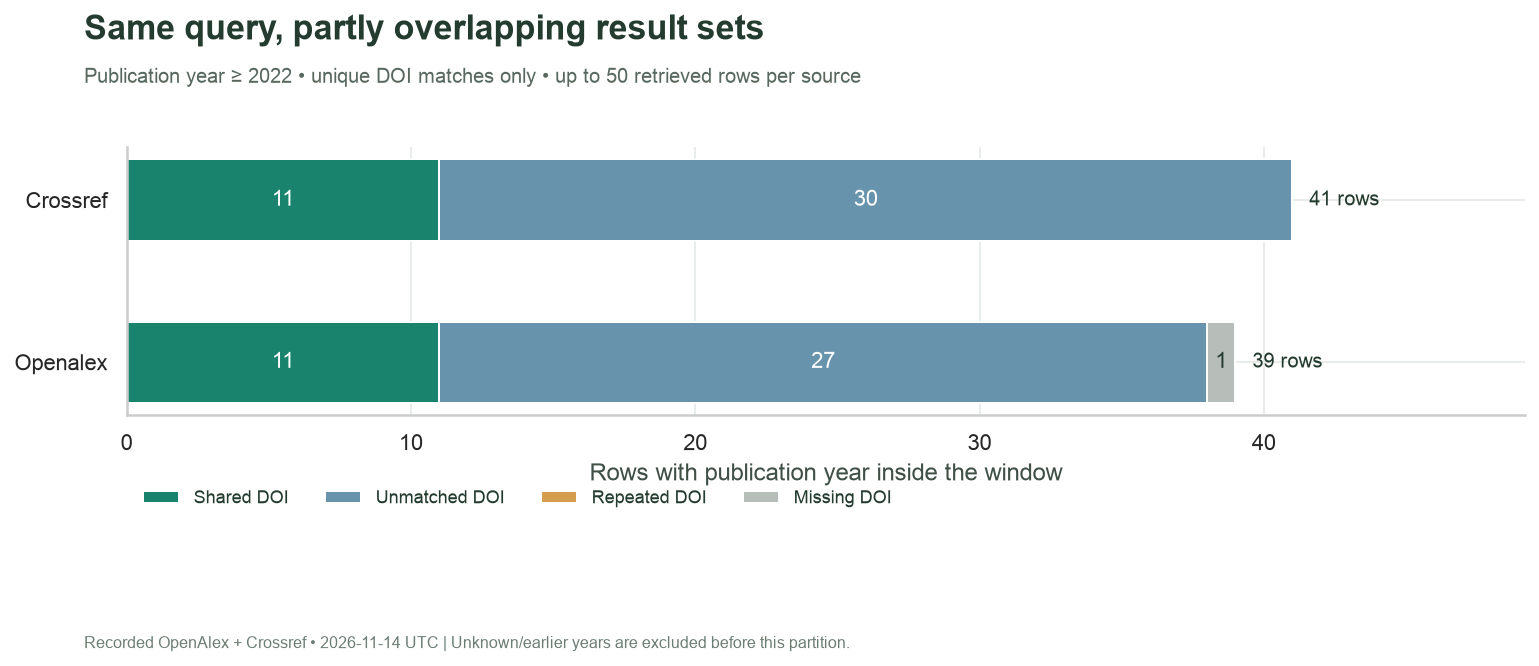

In [8]:
fig, ax = plt.subplots(figsize=(11, 4.6))
y = np.arange(len(coverage_frame))
left = np.zeros(len(y))
for column, label, color in [
    ("shared_doi", "Shared DOI", "#19836D"),
    ("unmatched_doi", "Unmatched DOI", "#6893AD"),
    ("ambiguous_doi", "Repeated DOI", "#D59E4E"),
    ("missing_doi", "Missing DOI", "#B7BDB8"),
]:
    values = coverage_frame[column].to_numpy(dtype=float)
    ax.barh(y, values, left=left, color=color, label=label, height=0.5)
    for row, value, start in zip(y, values, left, strict=True):
        if value:
            ax.text(
                start + value / 2,
                row,
                str(int(value)),
                ha="center",
                va="center",
                fontsize=11,
                color="white" if color in ["#19836D", "#6893AD"] else "#243B2F",
            )
    left += values
for row, total in zip(y, left, strict=True):
    ax.text(total + 0.6, row, f"{int(total)} rows", va="center", fontsize=10)
ax.set_yticks(y, coverage_frame.source.str.title())
ax.invert_yaxis()
ax.set_xlim(0, max(10, max(left, default=0) * 1.2))
ax.set_xlabel("Rows with publication year inside the window")
ax.legend(ncol=4, loc="upper left", bbox_to_anchor=(0, -0.22), fontsize=9)
chart(
    fig,
    "Same query, partly overlapping result sets",
    f"Publication year ≥ {MIN_YEAR} • unique DOI matches only • up to 50 retrieved rows per source",
    source_label + " | Unknown/earlier years are excluded before this partition.",
)

In [9]:
shared = int(coverage_frame.shared_doi.min()) if len(coverage_frame) else 0
eligible_total = int(coverage_frame.eligible_rows.sum())
prose(
    f"The selected windows contain **{eligible_total} provider rows** and **{shared} shared DOI keys**. "
    f"Missing-DOI rows: **{int(coverage_frame.missing_doi.sum())}**; "
    f"repeated-DOI rows excluded: **{int(coverage_frame.ambiguous_doi.sum())}**. "
    "A shared work contributes one row in each provider, so shared bars should be equal. "
    "This is overlap of two search samples, not provider recall or the size of the literature."
)

The selected windows contain **80 provider rows** and **11 shared DOI keys**. Missing-DOI rows: **1**; repeated-DOI rows excluded: **0**. A shared work contributes one row in each provider, so shared bars should be equal. This is overlap of two search samples, not provider recall or the size of the literature.

## Compare observations attached to the same DOI

Keep both provider years, titles and citation counts in the joined table. The signed difference is **OpenAlex minus Crossref**, in citations. A disagreement may reflect coverage or update timing; this notebook does not resolve which count is preferable. Zero counts stay plotted at zero. A missing count remains NULL and is omitted from the paired chart, with its count stated below. All joined rows appear in the table; the chart shows up to 15 complete pairs with the largest absolute count differences.

In [10]:
%%sql pairs <<
SELECT * FROM matched ORDER BY abs(count_difference) DESC NULLS LAST,doi_key;

Running query in 'DuckDBPyConnection'

,doi_key,openalex_title,crossref_title,openalex_year,crossref_year,openalex_citations,crossref_citations,count_difference
0,10.1080/15481603.2024.2380126,Cross attention is all you need: relational re...,Cross attention is all you need: relational re...,2024,2024,53,41,12
1,10.1016/j.irfa.2023.102876,Attention is all you need: An interpretable tr...,Attention is all you need: An interpretable tr...,2023,2023,52,41,11
2,10.22323/1.453.0001,Equivariant transformer is all you need,Equivariant transformer is all you need,2023,2023,11,5,6
3,10.1007/978-981-19-1018-0_52,Attention Is All You Need to Tell: Transformer...,Attention Is All You Need to Tell: Transformer...,2022,2022,3,2,1
4,10.1007/978-3-031-84300-6_13,Is Attention All You Need?,Is Attention All You Need?,2025,2025,55,55,0
5,10.1016/s2152-2650(26)01057-8,POSTER: HL-1613: Attention Is All You Need for...,POSTER: HL-1613: Attention Is All You Need for...,2026,2026,0,0,0
6,10.1016/s2152-2650(26)02509-7,HL-1613: Attention Is All You Need for De-Esca...,HL-1613: Attention Is All You Need for De-Esca...,2026,2026,0,0,0
7,10.2139/ssrn.5967774,Attention is All You Need... Unless You Are a ...,Attention is All You Need... Unless You Are a ...,2026,2026,0,0,0
8,10.2139/ssrn.6096874,Attention via Synaptic Plasticity is All You N...,Attention via Synaptic Plasticity is All You N...,2026,2026,1,1,0
9,10.2139/ssrn.7499639,Failure Is All You Need — Attention as Reverse...,Failure Is All You Need — Attention as Reverse...,2026,2026,0,0,0


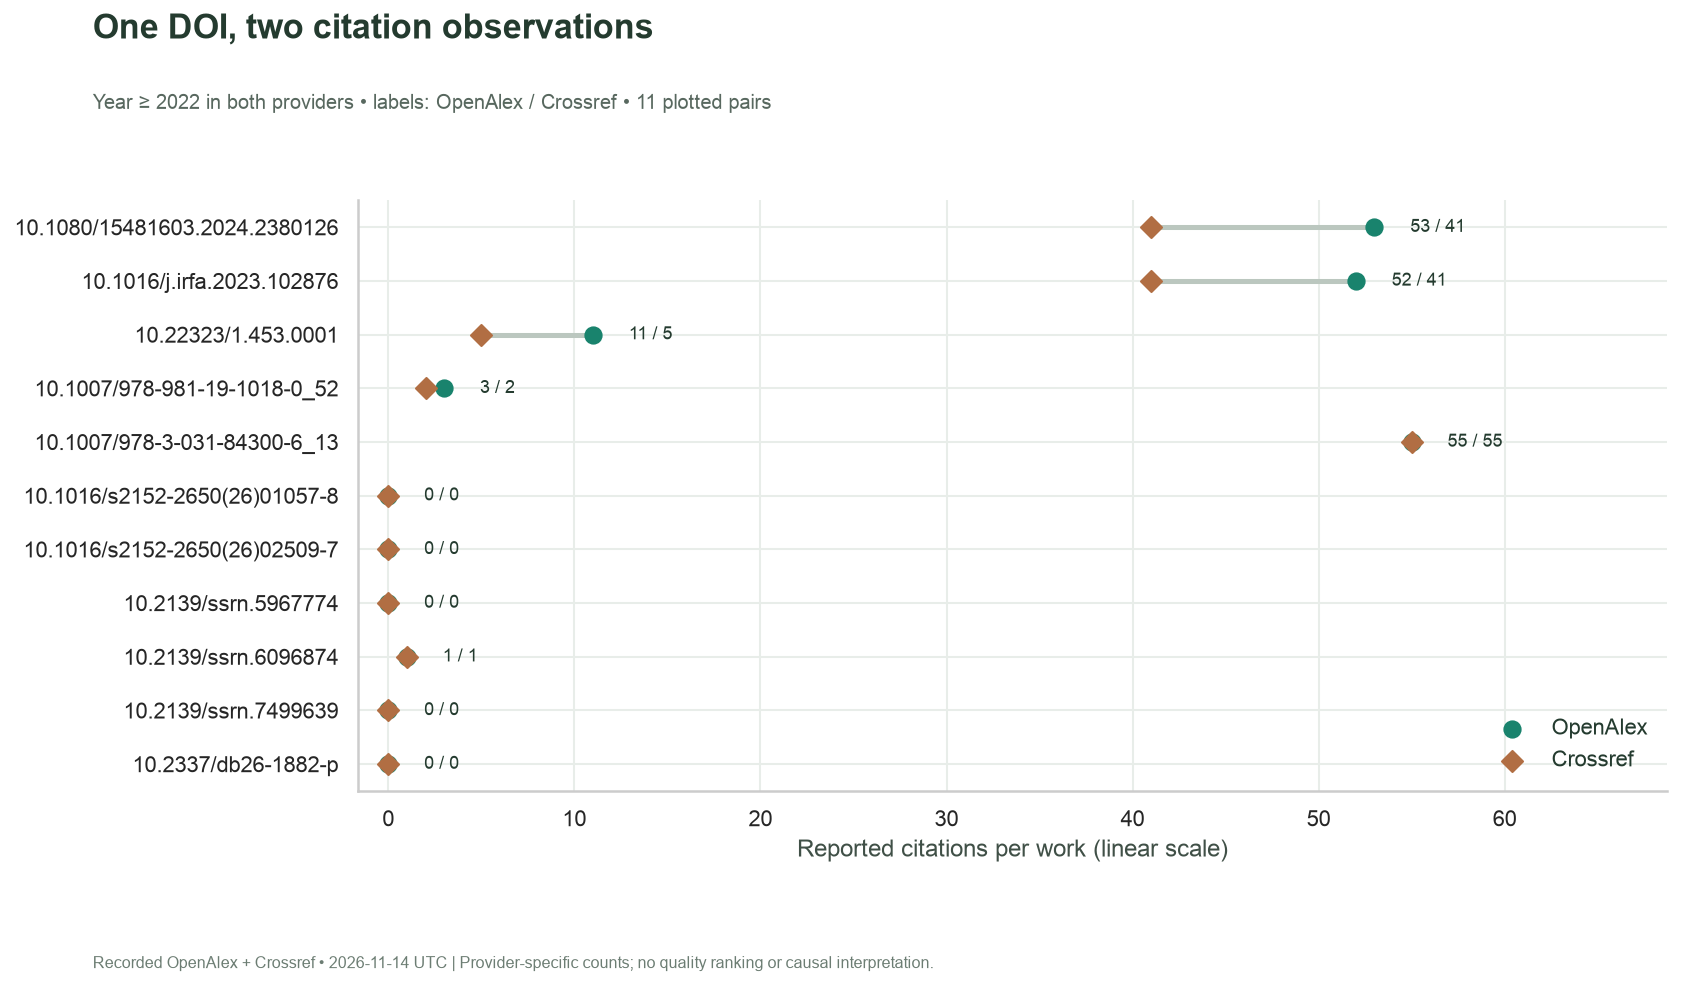

In [11]:
display(pairs)
complete = pairs.dropna(subset=["openalex_citations", "crossref_citations"]).head(15).copy()
fig, ax = plt.subplots(figsize=(12, max(5.2, len(complete) * 0.43 + 2.2)))
if len(complete):
    y = np.arange(len(complete))
    a = complete.openalex_citations.to_numpy(dtype=float)
    b = complete.crossref_citations.to_numpy(dtype=float)
    ax.hlines(y, np.minimum(a, b), np.maximum(a, b), color="#BBC7BF", linewidth=2.5)
    ax.scatter(a, y, color="#19836D", s=65, label="OpenAlex", zorder=3)
    ax.scatter(b, y, color="#B16E43", s=55, marker="D", label="Crossref", zorder=4)
    ax.set_yticks(y, complete.doi_key)
    ax.invert_yaxis()
    xmax = max(1, max(a), max(b))
    ax.set_xlim(-0.03 * xmax, 1.25 * xmax)
    for row, oa, cr in zip(y, a, b, strict=True):
        ax.text(max(oa, cr) + 0.035 * xmax, row, f"{int(oa):,} / {int(cr):,}", va="center", fontsize=9)
    ax.legend(loc="lower right")
    ax.set_xlabel("Reported citations per work (linear scale)")
else:
    ax.text(0.5, 0.5, "No shared DOI with both counts available", transform=ax.transAxes, ha="center")
    ax.set_axis_off()
chart(
    fig,
    "One DOI, two citation observations",
    f"Year ≥ {MIN_YEAR} in both providers • labels: OpenAlex / Crossref • {len(complete)} plotted pairs",
    source_label + " | Provider-specific counts; no quality ranking or causal interpretation.",
)

In [12]:
missing_pairs = int(pairs[["openalex_citations", "crossref_citations"]].isna().any(axis=1).sum())
unequal = int((pairs.count_difference.dropna() != 0).sum())
year_disagreement = int((pairs.openalex_year != pairs.crossref_year).sum())
prose(
    f"Of **{len(pairs)} shared DOI keys**, **{missing_pairs}** lack a paired citation observation; "
    f"**{unequal}** have unequal available counts and **{year_disagreement}** have different provider years. "
    "The DOI join establishes identifier agreement only. "
    "It does not equate titles, editions or indexing policies beyond that key. " + audit(server)
)

Of **11 shared DOI keys**, **0** lack a paired citation observation; **4** have unequal available counts and **0** have different provider years. The DOI join establishes identifier agreement only. It does not equate titles, editions or indexing policies beyond that key. Replay audit: exactly one request to each recorded provider; query and page parameters matched.

## Check the reconciliation

These relationships hold for either data mode and any supported year cutoff, including an empty selected window. They do not require the recorded number of matches, a particular citation ranking, or agreement between provider measurements.

In [13]:
%%sql checks <<
SELECT 'retrieval budgets' AS check_name,(SELECT count(*) FROM openalex_raw)<=50 AND (SELECT count(*) FROM crossref_raw)<=50 AS passed
UNION ALL SELECT 'source labels',NOT EXISTS(SELECT 1 FROM normalized WHERE source NOT IN ('openalex','crossref'))
UNION ALL SELECT 'inclusive year window',NOT EXISTS(SELECT 1 FROM eligible WHERE year IS NULL OR year<(SELECT min_year FROM settings))
UNION ALL SELECT 'unique provider DOI keys',NOT EXISTS(SELECT source,doi_key FROM unique_dois GROUP BY ALL HAVING count(*)<>1)
UNION ALL SELECT 'matched DOI uniqueness',(SELECT count(*)=count(DISTINCT doi_key) FROM matched)
UNION ALL SELECT 'matched DOI nonmissing',NOT EXISTS(SELECT 1 FROM matched WHERE doi_key IS NULL OR doi_key='')
UNION ALL SELECT 'both years qualify',NOT EXISTS(SELECT 1 FROM matched WHERE least(openalex_year,crossref_year)<(SELECT min_year FROM settings))
UNION ALL SELECT 'availability reconciles',NOT EXISTS(SELECT 1 FROM complete_coverage WHERE retrieved_rows<>unknown_year+earlier_year+eligible_rows)
UNION ALL SELECT 'selected rows partition',NOT EXISTS(SELECT 1 FROM complete_coverage WHERE eligible_rows<>missing_doi+ambiguous_doi+unmatched_doi+shared_doi)
UNION ALL SELECT 'shared bars equal joined keys',NOT EXISTS(SELECT 1 FROM complete_coverage WHERE shared_doi<>(SELECT count(*) FROM matched))
UNION ALL SELECT 'counts nonnegative when present',NOT EXISTS(SELECT 1 FROM normalized WHERE citations_count<0)
UNION ALL SELECT 'difference preserves missingness',NOT EXISTS(SELECT 1 FROM matched WHERE (count_difference IS NULL)<>(openalex_citations IS NULL OR crossref_citations IS NULL));

Running query in 'DuckDBPyConnection'

In [14]:
display(checks)
assert checks.passed.all(), checks.loc[~checks.passed].to_dict("records")
prose(f"**All {len(checks)} SQL checks passed.** " + audit(server))

,check_name,passed
0,retrieval budgets,True
1,source labels,True
2,inclusive year window,True
3,unique provider DOI keys,True
4,matched DOI uniqueness,True
5,matched DOI nonmissing,True
6,both years qualify,True
7,availability reconciles,True
8,selected rows partition,True
9,shared bars equal joined keys,True


**All 12 SQL checks passed.** Replay audit: exactly one request to each recorded provider; query and page parameters matched.

## Experiment: narrow the publication window

Change only **MIN_YEAR from 2022 to 2024** in replay mode and rerun into a separate output directory. Predict that eligible row counts cannot increase; a DOI can leave the overlap when either source year falls outside the new window. Compare the first chart, joined DOI table and paired counts for surviving keys. The captured source responses remain identical.

This experiment measures sensitivity to a local date filter, not a change in search query, indexing coverage or scholarly impact. A future live run may change the records themselves. Restore **2022** to return to the saved example; [the README](README.md) gives both experiment and live commands.

In [15]:
connection.close()
cleanup(server, thread, previous)

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" width="240" alt="Query.Farm"></a>